# Model 2 — Random forest
**Question:** Which behavioral characteristics best predict 1-year % weight change among U.S. adults who tried to lose weight, beyond demographics and starting BMI? (NHANES Aug 2021–Aug 2023, n = 2,794)

**Design:** a random forest is fitted twice:
- **Covariates only** — 15 demographic predictors + BMI 1 year ago
- **Covariates + behaviors** — the 15 above plus 12 behavioral predictors

A random forest grows many decision trees, each on a random sample of people and considering a random subset of predictors at each split, and averages their predictions. It can capture **non-linear** relationships and **interactions** without these being specified in advance.

Comparing the two fits (ΔR², ΔRMSE on the held-out test set, with bootstrap CIs) answers "beyond demographics and starting BMI"; permutation importance and SHAP values answer "which behaviors". A final section uses the forest for **feature selection** (Boruta-style shadow-feature test).

Outcome: `pct_wt_change` = (current − 1 yr ago) ÷ 1 yr ago × 100, restricted to ±50%. Negative = weight lost.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, cross_validate
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
DATA_PATH = "nhanes_model_ready.csv"   # keep the CSV next to this notebook
OUTCOME = "pct_wt_change"

# NHANES design variables: kept for reference, never used as predictors
ID_COL, WT_COL = "Respondent sequence number", "Full sample 2-year MEC exam weight"
# Set to True to fit and score with the MEC exam weights (population-weighted fit).
# Default False: a standard (unweighted) prediction model, as most ML comparisons do.
USE_SURVEY_WEIGHTS = False
N_JOBS = -1

pd.set_option("display.width", 140)
import shap
from scipy.stats import randint, uniform, binomtest
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance

# ---- figure style (used for every plot; figures are also saved to ./figures for reports)
import os, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
os.makedirs("figures", exist_ok=True)
SLOT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a"}
GRAY, INK, MUTED = "#a3a29c", "#0b0b0b", "#52514e"
BEH_COLOR, COV_COLOR = SLOT["orange"], GRAY
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cfe1f7", "#2a78d6", "#0b3d7a"])
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 9, "axes.titlesize": 10.5, "axes.titleweight": "bold", "legend.frameon": False,
})
def savefig(name):
    plt.savefig(f"figures/{name}.png")

LABELS = {
    "bmi_1yr_ago": "BMI 1 yr ago", "age": "Age", "female": "Female", "education": "Education",
    "income_poverty_ratio": "Income-to-poverty ratio", "household_size": "Household size",
    "us_born": "U.S.-born", "veteran": "Veteran",
    "race_eth_Mexican American": "Mexican American", "race_eth_Other Hispanic": "Other Hispanic",
    "race_eth_NH Black": "NH Black", "race_eth_NH Asian": "NH Asian", "race_eth_Other/Multiracial": "Other/Multiracial",
    "marital_Widowed/divorced/separated": "Widowed/divorced/sep.", "marital_Never married": "Never married",
    "mod_min_wk": "Moderate activity (min/wk)", "vig_min_wk": "Vigorous activity (min/wk)",
    "sedentary_hr_day": "Sedentary (hr/day)", "phq9_score": "Depressive symptoms (PHQ-9)",
    "drinks_per_week": "Drinks/week", "sleep_hr_avg": "Sleep (hr)",
    "smoking_status_Former": "Former smoker", "smoking_status_Current": "Current smoker",
    "main_meal_planner": "Main meal planner", "shares_meal_planning": "Shares meal planning",
    "main_food_shopper": "Main food shopper", "shares_food_shopping": "Shares food shopping",
}
nice = lambda c: LABELS.get(c, c)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load data and define predictor sets
The CSV is already cleaned, but a few predictors still have missing values (notably PHQ-9, drinks/week and income-to-poverty ratio, each ~12%). scikit-learn's random forest (version ≥ 1.4) handles missing values natively (it learns which side of each split missing values go to), so no imputation is needed.

In [ ]:
df = pd.read_csv(DATA_PATH)

COVARIATES = [
    "age", "female",
    "race_eth_Mexican American", "race_eth_Other Hispanic", "race_eth_NH Black",
    "race_eth_NH Asian", "race_eth_Other/Multiracial",
    "education", "income_poverty_ratio",
    "marital_Widowed/divorced/separated", "marital_Never married",
    "household_size", "us_born", "veteran", "bmi_1yr_ago",
]
BEHAVIORS = [
    "mod_min_wk", "vig_min_wk", "sedentary_hr_day", "phq9_score",
    "drinks_per_week", "sleep_hr_avg",
    "smoking_status_Former", "smoking_status_Current",
    "main_meal_planner", "shares_meal_planning", "main_food_shopper", "shares_food_shopping",
]
FULL = COVARIATES + BEHAVIORS
assert len(COVARIATES) == 15 and len(BEHAVIORS) == 12
assert set(FULL).issubset(df.columns)

print(df.shape)
print(f"Outcome: mean {df[OUTCOME].mean():.2f}%, SD {df[OUTCOME].std():.2f}%, range {df[OUTCOME].min():.1f} to {df[OUTCOME].max():.1f}")
miss = df[FULL].isna().sum()
print("\nPredictors with missing values (handled natively by the forest):")
print(miss[miss > 0].sort_values(ascending=False).to_frame("n_missing").assign(pct=lambda t: (100 * t.n_missing / len(df)).round(1)))

(2794, 33)
Outcome: mean -1.22%, SD 8.85%, range -40.1 to 50.0

Predictors with missing values (handled natively by the forest):
                                    n_missing   pct
drinks_per_week                           346  12.4
phq9_score                                333  11.9
income_poverty_ratio                      325  11.6
sleep_hr_avg                               34   1.2
mod_min_wk                                 15   0.5
vig_min_wk                                 15   0.5
bmi_1yr_ago                                11   0.4
sedentary_hr_day                            9   0.3
smoking_status_Former                       2   0.1
smoking_status_Current                      2   0.1
marital_Never married                       1   0.0
marital_Widowed/divorced/separated          1   0.0
shares_meal_planning                        1   0.0
main_food_shopper                           1   0.0


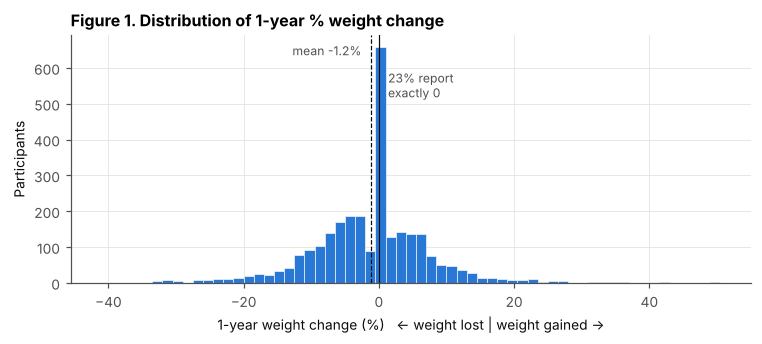

In [ ]:
# Figure 1: distribution of the outcome
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(df[OUTCOME], bins=np.arange(-41, 51, 1.5), color=SLOT["blue"], edgecolor="white", linewidth=0.4)
ax.axvline(0, color=INK, lw=0.8); ax.axvline(df[OUTCOME].mean(), color=INK, lw=0.8, ls="--")
ax.annotate(f"mean {df[OUTCOME].mean():.1f}%", (df[OUTCOME].mean(), ax.get_ylim()[1] * 0.92),
            xytext=(-6, 0), textcoords="offset points", ha="right", fontsize=8, color=MUTED)
ax.annotate(f"{100 * (df[OUTCOME] == 0).mean():.0f}% report\nexactly 0", (0, ax.get_ylim()[1] * 0.75),
            xytext=(6, 0), textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xlabel("1-year weight change (%)   ← weight lost | weight gained →"); ax.set_ylabel("Participants")
ax.set_title("Figure 1. Distribution of 1-year % weight change", loc="left")
plt.tight_layout(); savefig("m3_fig1_outcome_distribution"); plt.show()

## 2. Train / test split
One held-out test set (20%), stratified on outcome quintiles, with a fixed random seed for reproducibility. All tuning happens with cross-validation on the training set only.

In [ ]:
y = df[OUTCOME]
w = df[WT_COL] if USE_SURVEY_WEIGHTS else pd.Series(1.0, index=df.index)

# stratify on outcome quintiles so the heavy tails land in both sets
strata = pd.qcut(y, 5, labels=False, duplicates="drop")
idx_train, idx_test = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE, stratify=strata)

y_train, y_test = y.loc[idx_train], y.loc[idx_test]
w_train, w_test = w.loc[idx_train], w.loc[idx_test]
print(f"train n={len(idx_train)}, test n={len(idx_test)}")
print(f"train mean={y_train.mean():.2f}, test mean={y_test.mean():.2f}")

train n=2235, test n=559
train mean=-1.30, test mean=-0.91


In [ ]:
def metrics(y_true, y_pred, weights=None):
    return {
        "R2": r2_score(y_true, y_pred, sample_weight=weights),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred, sample_weight=weights)),
        "MAE": mean_absolute_error(y_true, y_pred, sample_weight=weights),
    }

def bootstrap_delta(y_true, pred_a, pred_b, weights=None, n_boot=2000, seed=RANDOM_STATE):
    """Paired bootstrap on the test set: change in R2 and RMSE going from model A to model B."""
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    wts = np.ones_like(y_true) if weights is None else np.asarray(weights)
    d_r2, d_rmse = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        ma, mb = metrics(y_true[i], pred_a[i], wts[i]), metrics(y_true[i], pred_b[i], wts[i])
        d_r2.append(mb["R2"] - ma["R2"]); d_rmse.append(mb["RMSE"] - ma["RMSE"])
    out = {}
    for name, arr in [("dR2", np.array(d_r2)), ("dRMSE", np.array(d_rmse))]:
        out[name] = (arr.mean(), *np.percentile(arr, [2.5, 97.5]))
    return out

TEST_W = w_test.values if USE_SURVEY_WEIGHTS else None
FIT_W = w_train.values if USE_SURVEY_WEIGHTS else None

In [ ]:
# Reference point: predict the training mean for everyone
baseline_pred = np.full(len(y_test), np.average(y_train, weights=w_train))
pd.DataFrame([metrics(y_test, baseline_pred, TEST_W)], index=["Mean-only baseline"]).round(3)

,R2,RMSE,MAE
Mean-only baseline,-0.002,9.089,6.28


## 3. Hyperparameter tuning
Randomized search (30 candidates × 5-fold CV on the training set, 300 trees each), separately for each predictor set. Key settings: maximum depth and minimum leaf size (how specific each tree can get), `max_features` (share of predictors each split may consider; smaller values make trees more different from each other) and `max_samples` (share of people each tree sees). The final forests use 1,000 trees with the chosen settings. Tuning takes a few minutes.

In [ ]:
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
FEATURE_SETS = {"Covariates": COVARIATES, "Covariates + behaviors": FULL}

param_dist = {
    "max_depth": [4, 6, 8, 12, None],
    "min_samples_leaf": randint(5, 80),
    "max_features": [0.2, 0.33, 0.5, 0.7, 1.0],
    "max_samples": uniform(0.5, 0.5),
}
base = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS)

searches = {}
for s_name, cols in FEATURE_SETS.items():
    s = RandomizedSearchCV(base, param_dist, n_iter=30, cv=CV, scoring="neg_root_mean_squared_error",
                           random_state=RANDOM_STATE, n_jobs=1, refit=False)
    s.fit(df.loc[idx_train, cols], y_train, sample_weight=FIT_W)
    searches[s_name] = s
    print(f"{s_name}: best CV RMSE = {-s.best_score_:.3f}")
    print("   ", {k: round(float(v), 4) if isinstance(v, (float, np.floating)) else v for k, v in s.best_params_.items()})

Covariates: best CV RMSE = 8.202
    {'max_depth': 4, 'max_features': 0.7, 'max_samples': 0.5911, 'min_samples_leaf': 8}


Covariates + behaviors: best CV RMSE = 8.161
    {'max_depth': 6, 'max_features': 0.7, 'max_samples': 0.9869, 'min_samples_leaf': 19}


## 4. Test-set performance

In [ ]:
fitted, preds, rows = {}, {}, []
for s_name, cols in FEATURE_SETS.items():
    m = RandomForestRegressor(n_estimators=1000, random_state=RANDOM_STATE, n_jobs=N_JOBS, **searches[s_name].best_params_)
    m.fit(df.loc[idx_train, cols], y_train, sample_weight=FIT_W)
    p = m.predict(df.loc[idx_test, cols])
    fitted[s_name], preds[s_name] = m, p
    rows.append({"Model": "Random forest", "Predictors": s_name, "CV RMSE": -searches[s_name].best_score_,
                 **metrics(y_test, p, TEST_W)})
results = pd.DataFrame(rows).set_index(["Model", "Predictors"])
results.round(4)

CV RMSE      R2    RMSE     MAE
Model         Predictors                                             
Random forest Covariates               8.2023  0.0711  8.7520  6.0647
              Covariates + behaviors   8.1609  0.0736  8.7402  6.0927

## 5. Do behaviors add predictive value?
**Test set:** paired bootstrap of ΔR² and ΔRMSE (covariates → covariates + behaviors).
**Repeated CV:** 5-fold × 5 repeats on the training set, with each predictor set's tuned hyperparameters held fixed (300 trees per fit).

In [ ]:
d = bootstrap_delta(y_test, preds["Covariates"], preds["Covariates + behaviors"], TEST_W)
delta_test = pd.DataFrame([{"Model": "Random forest",
    "ΔR² (test)": d["dR2"][0], "ΔR² 95% CI": f"[{d['dR2'][1]:.3f}, {d['dR2'][2]:.3f}]",
    "ΔRMSE (test)": d["dRMSE"][0], "ΔRMSE 95% CI": f"[{d['dRMSE'][1]:.3f}, {d['dRMSE'][2]:.3f}]"}]).set_index("Model")
delta_test.round(4)

,ΔR² (test),ΔR² 95% CI,ΔRMSE (test),ΔRMSE 95% CI
Model,,,,
Random forest,0.0026,"[-0.015, 0.021]",-0.0121,"[-0.099, 0.069]"


In [ ]:
rcv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
def cv_forest(params, cols, n_trees=300):
    m = RandomForestRegressor(n_estimators=n_trees, random_state=RANDOM_STATE, n_jobs=N_JOBS, **params)
    return cross_validate(m, df.loc[idx_train, cols], y_train, cv=rcv, scoring=["r2", "neg_root_mean_squared_error"],
                          params={"sample_weight": FIT_W} if USE_SURVEY_WEIGHTS else None)
scores = {s_name: cv_forest(searches[s_name].best_params_, cols) for s_name, cols in FEATURE_SETS.items()}
diff = scores["Covariates + behaviors"]["test_r2"] - scores["Covariates"]["test_r2"]
cv_results = pd.DataFrame({s: {"CV R2 mean": r["test_r2"].mean(), "CV R2 SD": r["test_r2"].std(),
                               "CV RMSE mean": -r["test_neg_root_mean_squared_error"].mean()}
                           for s, r in scores.items()}).T
print(f"Mean ΔR² across folds: {diff.mean():.4f}  (behaviors better in {(diff > 0).sum()}/{len(diff)} folds)")
cv_results.round(4)

Mean ΔR² across folds: 0.0058  (behaviors better in 19/25 folds)


,CV R2 mean,CV R2 SD,CV RMSE mean
Covariates,0.1220,0.0275,8.2122
Covariates + behaviors,0.1278,0.0289,8.1842


### Visual summary of the comparison

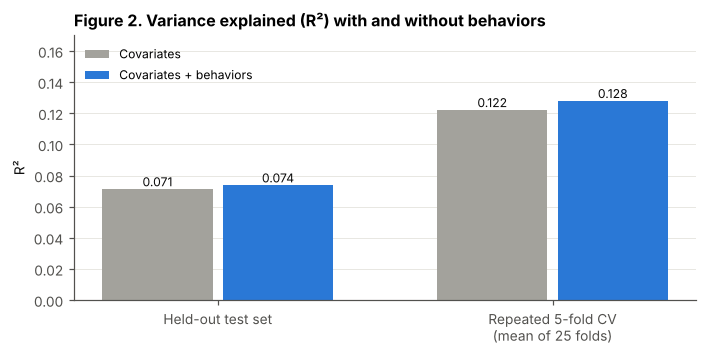

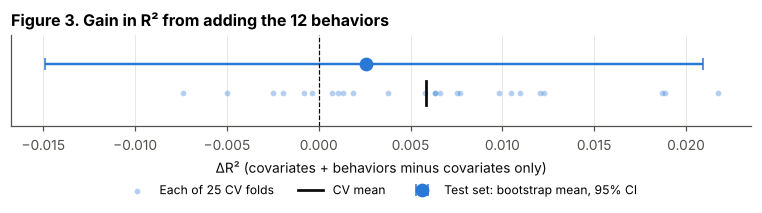

In [ ]:
# Figure 2: R² with and without behaviors
sets = ["Covariates", "Covariates + behaviors"]; cols_ = [COV_COLOR, SLOT["blue"]]
vals = {"Held-out test set": [results.loc[("Random forest", s), "R2"] for s in sets],
        "Repeated 5-fold CV\n(mean of 25 folds)": [scores[s]["test_r2"].mean() for s in sets]}
fig, ax = plt.subplots(figsize=(6.5, 3.3))
x = np.arange(len(vals)); wd = 0.36
for k, (s, col) in enumerate(zip(sets, cols_)):
    v = [vals[g][k] for g in vals]
    bars = ax.bar(x + (k - 0.5) * wd, v, width=wd - 0.03, color=col, label=s)
    for b, vv in zip(bars, v):
        ax.annotate(f"{vv:.3f}", (b.get_x() + b.get_width() / 2, vv), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
ax.set_xticks(x); ax.set_xticklabels(list(vals)); ax.set_ylabel("R²"); ax.set_ylim(0, 0.17)
ax.grid(axis="x", visible=False); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Figure 2. Variance explained (R²) with and without behaviors", loc="left")
plt.tight_layout(); savefig("m3_fig2_performance"); plt.show()

# Figure 3: gain in R² from adding behaviors
fig, ax = plt.subplots(figsize=(7, 2.6))
est, lo, hi = d["dR2"]
ax.errorbar(est, 0.15, xerr=[[est - lo], [hi - est]], fmt="o", ms=8, color=SLOT["blue"], capsize=4, lw=1.6,
            label="Test set: bootstrap mean, 95% CI")
ax.scatter(diff, np.full(len(diff), -0.2), s=14, color=SLOT["blue"], alpha=0.35, linewidths=0, label="Each of 25 CV folds")
ax.plot([diff.mean()] * 2, [-0.35, -0.05], color=INK, lw=1.8, label="CV mean")
ax.axvline(0, color=INK, lw=0.8, ls="--")
ax.set_ylim(-0.6, 0.5); ax.set_yticks([]); ax.grid(axis="y", visible=False)
ax.set_xlabel("ΔR² (covariates + behaviors minus covariates only)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.5), ncol=3, fontsize=8)
ax.set_title("Figure 3. Gain in R² from adding the 12 behaviors", loc="left")
plt.tight_layout(); savefig("m3_fig3_delta_r2"); plt.show()

## 6. Which behaviors matter?
Three complementary views on the full model:
1. **Permutation importance** (test set): how much test R² drops when a predictor is shuffled. Model-agnostic, so it does not depend on how the trees were built.
2. **Grouped permutation**: shuffle *all* behaviors together vs. all covariates together, to quantify the behavior block's total contribution.
3. **SHAP values**: direction and shape of each predictor's effect, per person.

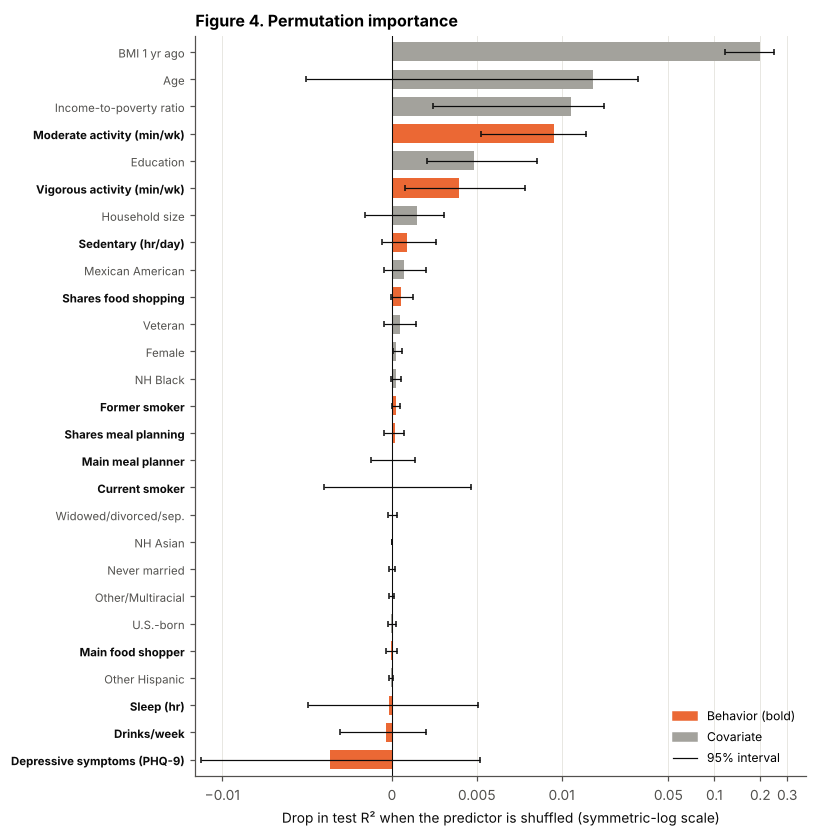

,mean_drop_R2,sd,ci_low,ci_high,group
bmi_1yr_ago,0.1996,0.0353,0.1170,0.2476,Covariate
age,0.0161,0.0092,-0.0050,0.0315,Covariate
income_poverty_ratio,0.0116,0.0039,0.0024,0.0188,Covariate
mod_min_wk,0.0096,0.0027,0.0053,0.0145,Behavior
education,0.0049,0.0019,0.0021,0.0085,Covariate
vig_min_wk,0.0040,0.0020,0.0008,0.0078,Behavior
household_size,0.0015,0.0015,-0.0016,0.0031,Covariate
sedentary_hr_day,0.0009,0.0009,-0.0006,0.0026,Behavior
race_eth_Mexican American,0.0007,0.0007,-0.0005,0.0020,Covariate
shares_food_shopping,0.0005,0.0004,-0.0000,0.0013,Behavior


In [ ]:
full = fitted["Covariates + behaviors"]
X_test_full = df.loc[idx_test, FULL]
pi = permutation_importance(full, X_test_full, y_test, scoring="r2", n_repeats=30,
                            random_state=RANDOM_STATE, sample_weight=TEST_W)
perm = pd.DataFrame({"mean_drop_R2": pi.importances_mean, "sd": pi.importances_std,
                     "ci_low": np.percentile(pi.importances, 2.5, axis=1),
                     "ci_high": np.percentile(pi.importances, 97.5, axis=1)}, index=FULL)
perm["group"] = ["Behavior" if c in BEHAVIORS else "Covariate" for c in perm.index]
perm = perm.sort_values("mean_drop_R2", ascending=False)

# Figure 4: permutation importance with 95% intervals over 30 shuffles
pp = perm.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 0.24 * len(pp) + 1.2))
yy = np.arange(len(pp))
ax.barh(yy, pp.mean_drop_R2, height=0.7, color=[BEH_COLOR if g == "Behavior" else COV_COLOR for g in pp.group])
ax.errorbar(pp.mean_drop_R2, yy, xerr=[pp.mean_drop_R2 - pp.ci_low, pp.ci_high - pp.mean_drop_R2],
            fmt="none", ecolor=INK, elinewidth=0.8, capsize=2)
ax.set_yticks(yy); ax.set_yticklabels([nice(c) for c in pp.index], fontsize=7.5)
for lab, g in zip(ax.get_yticklabels(), pp.group):
    if g == "Behavior": lab.set_fontweight("bold"); lab.set_color(INK)
ax.axvline(0, color=INK, lw=0.7); ax.grid(axis="y", visible=False); ax.set_ylim(-0.6, len(pp) - 0.4)
ax.set_xscale("symlog", linthresh=0.01); ax.set_xlim(-0.015, 0.4)
ax.set_xticks([-0.01, 0, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3]); ax.set_xticklabels(["−0.01", "0", "0.005", "0.01", "0.05", "0.1", "0.2", "0.3"])
ax.set_xlabel("Drop in test R² when the predictor is shuffled (symmetric-log scale)")
ax.legend(handles=[mpl.patches.Patch(color=BEH_COLOR, label="Behavior (bold)"), mpl.patches.Patch(color=COV_COLOR, label="Covariate"),
                   mpl.lines.Line2D([], [], color=INK, lw=0.8, label="95% interval")], loc="lower right", fontsize=8)
ax.set_title("Figure 4. Permutation importance", loc="left")
plt.tight_layout(); savefig("m3_fig4_permutation_importance"); plt.show()
perm.round(4)

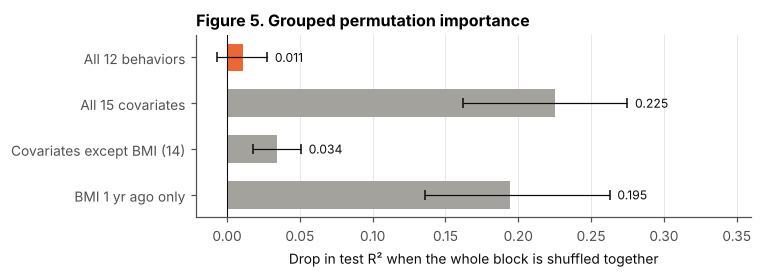

,mean_drop_R2,ci_low,ci_high
All 12 behaviors,0.0108,-0.0071,0.0276
All 15 covariates,0.2251,0.1617,0.2749
Covariates except BMI (14),0.0340,0.0178,0.0508
BMI 1 yr ago only,0.1946,0.1359,0.2628


In [ ]:
def grouped_permutation(model, X, y, groups, n_repeats=50, weights=None, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base_r2 = r2_score(y, model.predict(X), sample_weight=weights)
    out = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            perm_idx = rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].values[perm_idx]          # shuffle the block jointly, keeping within-block structure
            drops.append(base_r2 - r2_score(y, model.predict(Xp), sample_weight=weights))
        out[g] = {"mean_drop_R2": np.mean(drops), "ci_low": np.percentile(drops, 2.5), "ci_high": np.percentile(drops, 97.5)}
    return pd.DataFrame(out).T

GROUPS = {"All 12 behaviors": BEHAVIORS, "All 15 covariates": COVARIATES,
          "Covariates except BMI (14)": [c for c in COVARIATES if c != "bmi_1yr_ago"], "BMI 1 yr ago only": ["bmi_1yr_ago"]}
grp = grouped_permutation(full, X_test_full, y_test, GROUPS, weights=TEST_W)

# Figure 5: contribution of each block of predictors
g = grp.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 2.6))
colors = [BEH_COLOR if "behaviors" in k else COV_COLOR for k in g.index]
ax.barh(g.index, g.mean_drop_R2, height=0.6, color=colors)
ax.errorbar(g.mean_drop_R2, np.arange(len(g)), xerr=[g.mean_drop_R2 - g.ci_low, g.ci_high - g.mean_drop_R2],
            fmt="none", ecolor=INK, elinewidth=0.8, capsize=3)
for k, (name, r) in enumerate(g.iterrows()):
    ax.annotate(f"{r.mean_drop_R2:.3f}", (max(r.ci_high, r.mean_drop_R2), k), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK)
ax.axvline(0, color=INK, lw=0.7); ax.grid(axis="y", visible=False); ax.set_xlim(right=0.36)
ax.set_xlabel("Drop in test R² when the whole block is shuffled together")
ax.set_title("Figure 5. Grouped permutation importance", loc="left")
plt.tight_layout(); savefig("m3_fig5_grouped_importance"); plt.show()
grp.round(4)

### SHAP
Each dot is one test-set participant. Position on the x-axis = how much that predictor pushed their predicted weight change up (gain) or down (loss); color = predictor value.

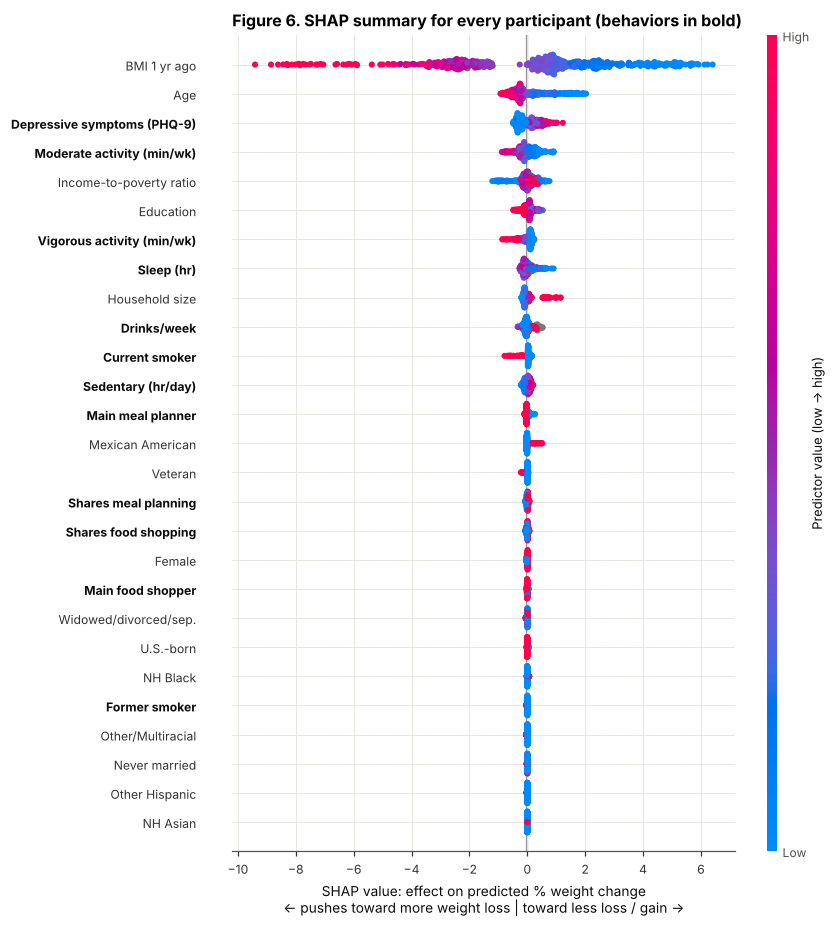

,mean_|SHAP|,group
bmi_1yr_ago,2.5059,Covariate
age,0.4848,Covariate
phq9_score,0.2968,Behavior
mod_min_wk,0.2316,Behavior
income_poverty_ratio,0.1816,Covariate
education,0.1379,Covariate
vig_min_wk,0.1347,Behavior
sleep_hr_avg,0.1300,Behavior
household_size,0.1099,Covariate
drinks_per_week,0.1005,Behavior


In [ ]:
explainer = shap.TreeExplainer(full)
shap_values = explainer(X_test_full)

# Figure 6: SHAP summary (beeswarm) with readable names; behaviors in bold
sv_named = shap.Explanation(values=shap_values.values, base_values=shap_values.base_values,
                            data=shap_values.data, feature_names=[nice(c) for c in FULL])
shap.plots.beeswarm(sv_named, max_display=27, show=False, color_bar_label="Predictor value (low → high)")
fig = plt.gcf(); fig.set_size_inches(8, 8.5); ax = plt.gca()
beh_names = {nice(c) for c in BEHAVIORS}
for lab in ax.get_yticklabels():
    if lab.get_text() in beh_names: lab.set_fontweight("bold"); lab.set_color(INK)
    lab.set_fontsize(8)
ax.set_xlabel("SHAP value: effect on predicted % weight change\n← pushes toward more weight loss | toward less loss / gain →", fontsize=9)
ax.tick_params(axis="x", labelsize=8)
cax = fig.axes[-1]; cax.yaxis.label.set_size(8.5); cax.tick_params(labelsize=8)
ax.set_title("Figure 6. SHAP summary for every participant (behaviors in bold)", loc="left", fontsize=10.5, fontweight="bold")
plt.tight_layout(); savefig("m3_fig6_shap_beeswarm"); plt.show()

shap_imp = pd.Series(np.abs(shap_values.values).mean(0), index=FULL, name="mean_|SHAP|").sort_values(ascending=False)
shap_imp.to_frame().assign(group=lambda t: ["Behavior" if c in BEHAVIORS else "Covariate" for c in t.index]).round(4)

### Shape of the top behavioral effects
SHAP dependence plots for the four most important behaviors, colored by starting BMI. Curvature, thresholds or plateaus here are patterns a straight-line model could not represent.

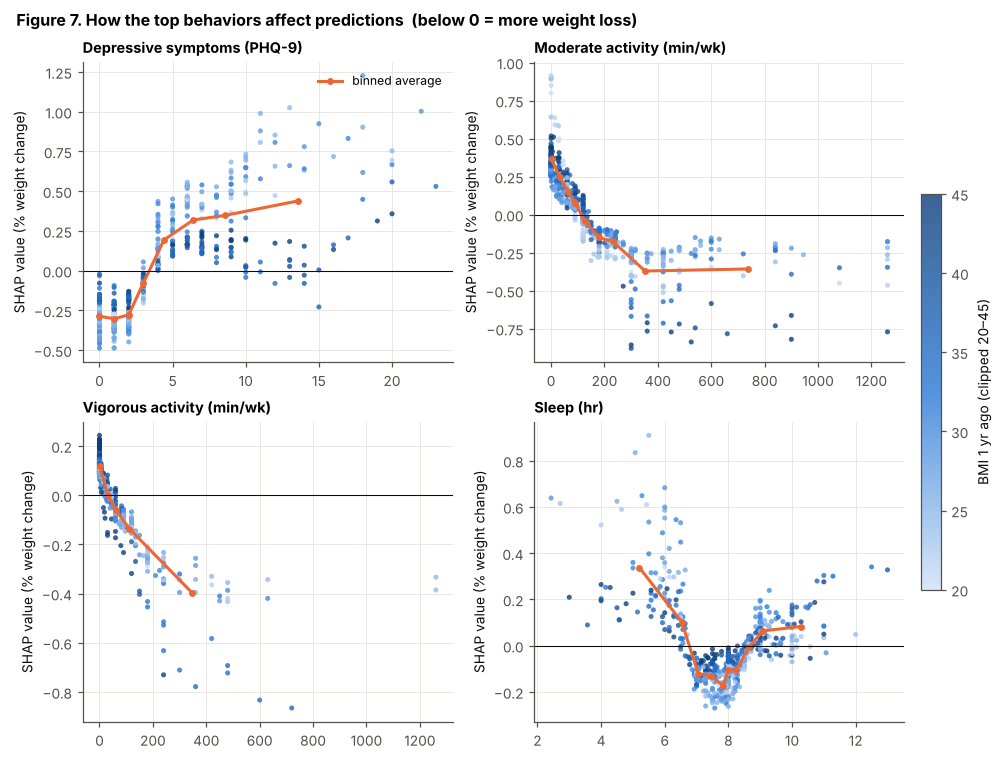

In [ ]:
# Figure 7: shape of the four most important behavioral effects (SHAP dependence)
top_beh = [c for c in shap_imp.index if c in BEHAVIORS][:4]
bmi = X_test_full["bmi_1yr_ago"].values
fig, axes = plt.subplots(2, 2, figsize=(9, 6.8), layout="constrained")
for ax, c in zip(axes.ravel(), top_beh):
    xv = X_test_full[c].values; sv = shap_values[:, c].values
    ok = ~np.isnan(xv)
    sc = ax.scatter(xv[ok], sv[ok], c=np.clip(bmi[ok], 20, 45), cmap=SEQ, s=11, alpha=0.8, linewidths=0)
    qs = np.unique(np.quantile(xv[ok], np.linspace(0, 1, 11)))
    if len(qs) > 2:
        idx = np.clip(np.digitize(xv[ok], qs[1:-1]), 0, len(qs) - 2)
        mx = [xv[ok][idx == k].mean() for k in range(len(qs) - 1) if (idx == k).any()]
        my = [sv[ok][idx == k].mean() for k in range(len(qs) - 1) if (idx == k).any()]
        ax.plot(mx, my, color=SLOT["orange"], lw=2, marker="o", ms=3.5, label="binned average")
    ax.axhline(0, color=INK, lw=0.7)
    ax.set_ylabel("SHAP value (% weight change)")
    ax.set_title(nice(c), fontsize=9.5, loc="left")
axes[0, 0].legend(loc="upper right", fontsize=8)
cb = fig.colorbar(sc, ax=axes, shrink=0.6, pad=0.02); cb.set_label("BMI 1 yr ago (clipped 20–45)")
fig.suptitle("Figure 7. How the top behaviors affect predictions  (below 0 = more weight loss)", x=0.01, ha="left",
             fontweight="bold", fontsize=10.5)
savefig("m3_fig7_shap_dependence"); plt.show()

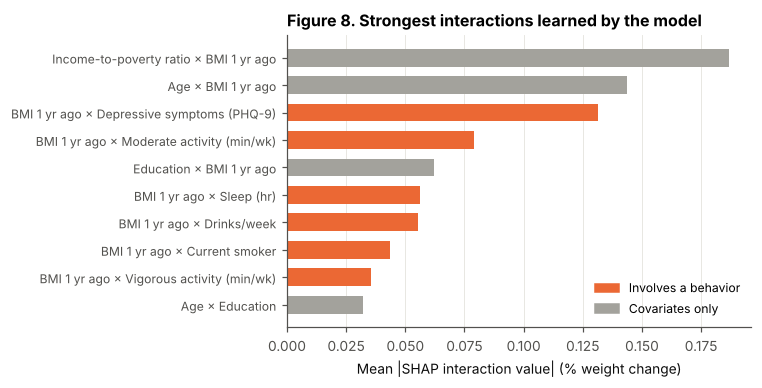

,feature_1,feature_2,mean_|interaction|,involves_behavior
185,income_poverty_ratio,bmi_1yr_ago,0.1869,False
13,age,bmi_1yr_ago,0.1437,False
276,bmi_1yr_ago,phq9_score,0.1313,True
273,bmi_1yr_ago,mod_min_wk,0.0791,True
167,education,bmi_1yr_ago,0.0619,False
278,bmi_1yr_ago,sleep_hr_avg,0.0563,True
277,bmi_1yr_ago,drinks_per_week,0.0555,True
280,bmi_1yr_ago,smoking_status_Current,0.0437,True
274,bmi_1yr_ago,vig_min_wk,0.0357,True
6,age,education,0.0321,False


In [ ]:
# Strongest pairwise interactions (SHAP interaction values; takes a few minutes for a 1,000-tree forest)
inter = explainer.shap_interaction_values(X_test_full)
m = np.abs(inter).mean(0); np.fill_diagonal(m, 0)
pairs = [(FULL[i], FULL[j], m[i, j]) for i in range(len(FULL)) for j in range(i + 1, len(FULL))]
inter_df = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "mean_|interaction|"]).sort_values("mean_|interaction|", ascending=False)
inter_df["involves_behavior"] = inter_df.feature_1.isin(BEHAVIORS) | inter_df.feature_2.isin(BEHAVIORS)

# Figure 8: ten strongest pairwise interactions
top = inter_df.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
labels = [f"{nice(a)} × {nice(b)}" for a, b in zip(top.feature_1, top.feature_2)]
ax.barh(labels, top["mean_|interaction|"], height=0.65,
        color=[BEH_COLOR if v else COV_COLOR for v in top.involves_behavior])
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("Mean |SHAP interaction value| (% weight change)")
ax.legend(handles=[mpl.patches.Patch(color=BEH_COLOR, label="Involves a behavior"), mpl.patches.Patch(color=COV_COLOR, label="Covariates only")],
          loc="lower right", fontsize=8)
ax.set_title("Figure 8. Strongest interactions learned by the model", loc="left")
plt.tight_layout(); savefig("m3_fig8_interactions"); plt.show()
inter_df.head(10).round(4)

## 7. Residual check

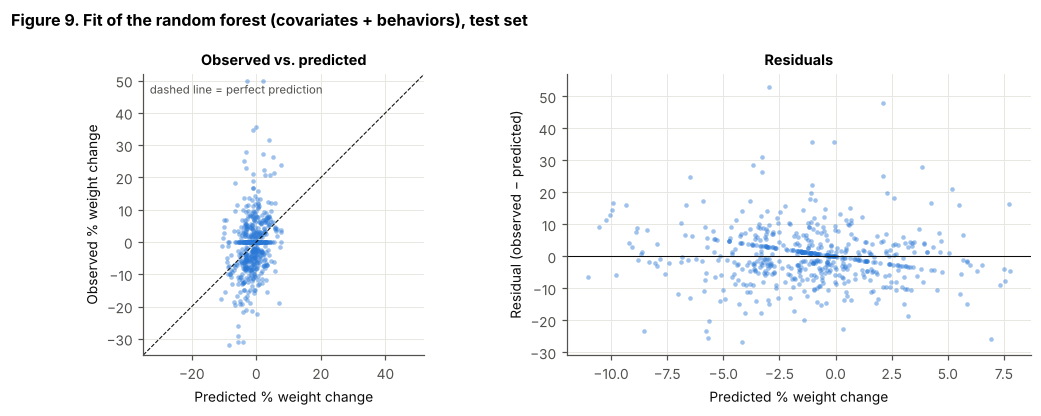

In [ ]:
# Figure 9: observed vs predicted, and residuals (test set)
p = preds["Covariates + behaviors"]
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
ax[0].scatter(p, y_test, s=9, alpha=0.45, color=SLOT["blue"], linewidths=0)
lim = [-35, 52]; ax[0].plot(lim, lim, color=INK, ls="--", lw=0.7)
ax[0].set_xlim(lim); ax[0].set_ylim(lim); ax[0].set_aspect("equal")
ax[0].set_xlabel("Predicted % weight change"); ax[0].set_ylabel("Observed % weight change")
ax[0].set_title("Observed vs. predicted", fontsize=9.5)
ax[0].annotate("dashed line = perfect prediction", (-33, 46), fontsize=7.5, color=MUTED)
ax[1].scatter(p, y_test - p, s=9, alpha=0.45, color=SLOT["blue"], linewidths=0); ax[1].axhline(0, color=INK, lw=0.7)
ax[1].set_xlabel("Predicted % weight change"); ax[1].set_ylabel("Residual (observed − predicted)")
ax[1].set_title("Residuals", fontsize=9.5)
fig.suptitle("Figure 9. Fit of the random forest (covariates + behaviors), test set", x=0.01, ha="left",
             fontweight="bold", fontsize=10.5)
plt.tight_layout(); savefig("m3_fig9_residuals"); plt.show()

## 8. Feature selection (Boruta-style shadow-feature test)
For each of 100 rounds, every predictor gets a **shadow** copy whose values are randomly shuffled, so shadows carry no real information. A forest (tuned settings, 200 trees) is trained on the real + shadow predictors, and each real predictor scores a **hit** if its impurity importance beats the *best* shadow. A useless predictor would win only by luck, so the hit count is tested against a 50% chance rate (binomial test, Bonferroni-corrected across 27 predictors): **confirmed**, **rejected** or **tentative**.

**Caution:** impurity importance favors continuous predictors. The best shadow is usually a shuffled continuous variable, which a 0/1 indicator (smoking, meal-planner roles) can almost never beat however real its effect. A rejection here means "not detectably better than noise by this measure", not "no effect"; read it together with the permutation results above.

In [ ]:
N_ROUNDS = 100
rng = np.random.default_rng(RANDOM_STATE)
params = searches["Covariates + behaviors"].best_params_
Xb = df.loc[idx_train, FULL].reset_index(drop=True)
hits = pd.Series(0, index=FULL)
shadow_max, real_imp = [], []
for r in range(N_ROUNDS):
    shadow = Xb.apply(lambda col: col.sample(frac=1.0, random_state=int(rng.integers(1e9))).values)
    shadow.columns = ["shadow_" + c for c in FULL]
    Xr = pd.concat([Xb, shadow], axis=1)
    rf = RandomForestRegressor(n_estimators=200, random_state=int(rng.integers(1e9)), n_jobs=N_JOBS, **params)
    rf.fit(Xr, y_train.values, sample_weight=FIT_W)
    fi = pd.Series(rf.feature_importances_, index=Xr.columns)
    smax = fi[shadow.columns].max()
    hits += (fi[FULL] > smax).astype(int)
    shadow_max.append(smax); real_imp.append(fi[FULL])
real_imp = pd.DataFrame(real_imp)

alpha = 0.05 / len(FULL)
def decide(h):
    if binomtest(h, N_ROUNDS, 0.5, alternative="greater").pvalue < alpha: return "Confirmed"
    if binomtest(h, N_ROUNDS, 0.5, alternative="less").pvalue < alpha: return "Rejected"
    return "Tentative"
boruta = pd.DataFrame({"hits": hits, "hit_rate_%": 100 * hits / N_ROUNDS, "median_importance": real_imp.median()})
boruta["decision"] = boruta["hits"].apply(decide)
boruta["group"] = ["Behavior" if c in BEHAVIORS else "Covariate" for c in boruta.index]
boruta["test_perm_drop_R2"] = perm["mean_drop_R2"]
boruta = boruta.sort_values("median_importance", ascending=False)
SELECTED = [c for c in boruta.index if boruta.loc[c, "decision"] == "Confirmed"]
SELECTED_STRICT = [c for c in SELECTED if perm.loc[c, "mean_drop_R2"] > 0]
print(boruta["decision"].value_counts().to_dict())
print("Boruta-confirmed:", [nice(c) for c in SELECTED])
print("Confirmed + positive test permutation importance:", [nice(c) for c in SELECTED_STRICT])
boruta.round(4)

{'Rejected': 21, 'Confirmed': 6}
Boruta-confirmed: ['BMI 1 yr ago', 'Age', 'Income-to-poverty ratio', 'Depressive symptoms (PHQ-9)', 'Moderate activity (min/wk)', 'Sleep (hr)']
Confirmed + positive test permutation importance: ['BMI 1 yr ago', 'Age', 'Income-to-poverty ratio', 'Moderate activity (min/wk)']


,hits,hit_rate_%,median_importance,decision,group,test_perm_drop_R2
bmi_1yr_ago,100,100.0,0.4709,Confirmed,Covariate,0.1996
age,100,100.0,0.0671,Confirmed,Covariate,0.0161
income_poverty_ratio,100,100.0,0.0589,Confirmed,Covariate,0.0116
phq9_score,99,99.0,0.0457,Confirmed,Behavior,-0.0037
mod_min_wk,88,88.0,0.0360,Confirmed,Behavior,0.0096
sleep_hr_avg,86,86.0,0.0332,Confirmed,Behavior,-0.0002
drinks_per_week,11,11.0,0.0229,Rejected,Behavior,-0.0003
vig_min_wk,1,1.0,0.0175,Rejected,Behavior,0.0040
household_size,0,0.0,0.0165,Rejected,Covariate,0.0015
education,0,0.0,0.0142,Rejected,Covariate,0.0049


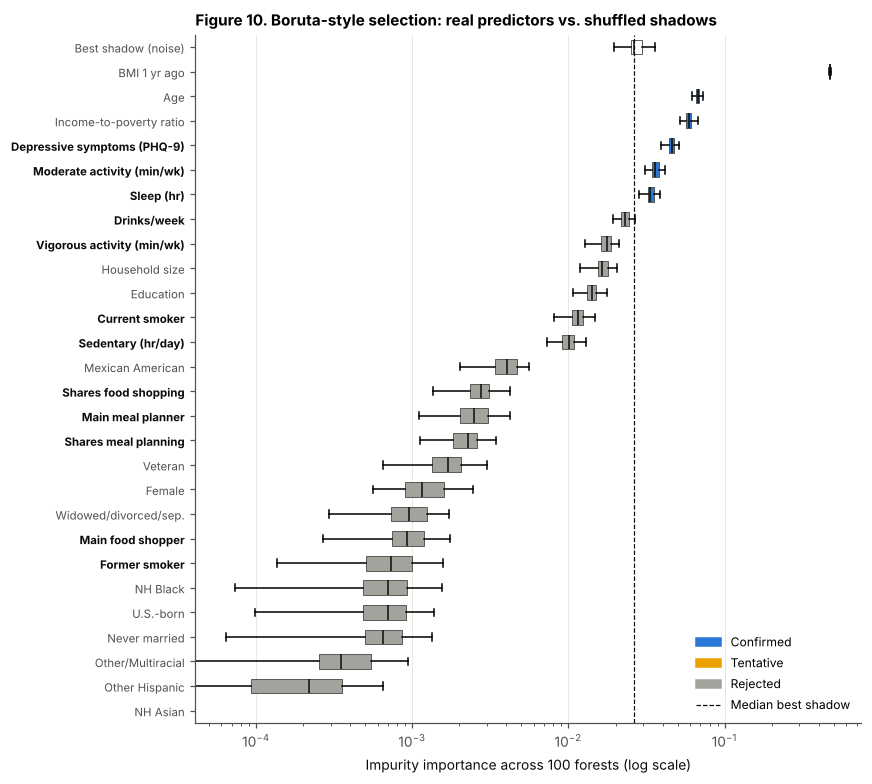

In [ ]:
# Figure 10: Boruta importance distributions vs. best shadow
order = boruta.sort_values("median_importance").index
dec_color = {"Confirmed": SLOT["blue"], "Tentative": "#eda100", "Rejected": GRAY}
fig, ax = plt.subplots(figsize=(8, 7.2))
data = [real_imp[c].values for c in order] + [np.array(shadow_max)]
labels = [nice(c) for c in order] + ["Best shadow (noise)"]
bp = ax.boxplot(data, orientation="horizontal", widths=0.6, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, lw=1))
for patch, c in zip(bp["boxes"], list(order) + ["shadow"]):
    patch.set_facecolor(dec_color[boruta.loc[c, "decision"]] if c != "shadow" else "#ffffff")
    patch.set_edgecolor(MUTED); patch.set_linewidth(0.6)
ax.axvline(np.median(shadow_max), color=INK, ls="--", lw=0.8)
ax.set_yticks(range(1, len(labels) + 1)); ax.set_yticklabels(labels, fontsize=7.5)
for lab, c in zip(ax.get_yticklabels(), list(order) + ["shadow"]):
    if c in BEHAVIORS: lab.set_fontweight("bold"); lab.set_color(INK)
ax.set_xscale("log"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Impurity importance across 100 forests (log scale)")
ax.legend(handles=[mpl.patches.Patch(color=v, label=k) for k, v in dec_color.items()] +
                  [mpl.lines.Line2D([], [], color=INK, ls="--", lw=0.8, label="Median best shadow")],
          loc="lower right", fontsize=8)
ax.set_title("Figure 10. Boruta-style selection: real predictors vs. shuffled shadows", loc="left", fontsize=10)
plt.tight_layout(); savefig("m3_fig10_boruta"); plt.show()

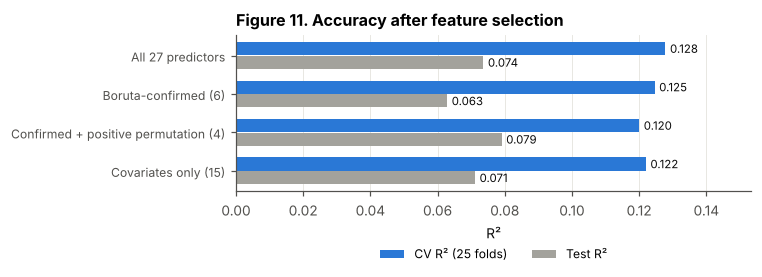

,n,CV R2 mean,CV R2 SD,Test R2,Test RMSE,Test MAE
Predictor set,,,,,,
All 27 predictors,27,0.1278,0.0289,0.0736,8.7402,6.0927
Boruta-confirmed (6),6,0.1246,0.0302,0.0628,8.7909,6.1331
Confirmed + positive permutation (4),4,0.1200,0.0283,0.0791,8.7145,6.0589
Covariates only (15),15,0.1220,0.0275,0.0711,8.7520,6.0647


In [ ]:
# Does a smaller predictor set lose accuracy?
subsets = {"All 27 predictors": FULL, f"Boruta-confirmed ({len(SELECTED)})": SELECTED,
           f"Confirmed + positive permutation ({len(SELECTED_STRICT)})": SELECTED_STRICT,
           "Covariates only (15)": COVARIATES}
sub_rows = []
for name, cols in subsets.items():
    p_ = searches["Covariates"].best_params_ if name == "Covariates only (15)" else searches["Covariates + behaviors"].best_params_
    r = cv_forest(p_, cols)
    mm = RandomForestRegressor(n_estimators=1000, random_state=RANDOM_STATE, n_jobs=N_JOBS, **p_).fit(df.loc[idx_train, cols], y_train, sample_weight=FIT_W)
    sub_rows.append({"Predictor set": name, "n": len(cols), "CV R2 mean": r["test_r2"].mean(), "CV R2 SD": r["test_r2"].std(),
                     **{f"Test {k}": v for k, v in metrics(y_test, mm.predict(df.loc[idx_test, cols]), TEST_W).items()}})
subset_results = pd.DataFrame(sub_rows).set_index("Predictor set")

# Figure 11: accuracy of each predictor subset
sr = subset_results.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 2.8))
yy = np.arange(len(sr))
ax.barh(yy + 0.18, sr["CV R2 mean"], height=0.34, color=SLOT["blue"], label="CV R² (25 folds)")
ax.barh(yy - 0.18, sr["Test R2"], height=0.34, color=COV_COLOR, label="Test R²")
for k, (cv, te) in enumerate(zip(sr["CV R2 mean"], sr["Test R2"])):
    ax.annotate(f"{cv:.3f}", (cv, k + 0.18), xytext=(3, 0), textcoords="offset points", va="center", fontsize=7.5, color=INK)
    ax.annotate(f"{te:.3f}", (te, k - 0.18), xytext=(3, 0), textcoords="offset points", va="center", fontsize=7.5, color=INK)
ax.set_yticks(yy); ax.set_yticklabels(sr.index, fontsize=8); ax.grid(axis="y", visible=False)
ax.set_xlabel("R²"); ax.set_xlim(0, max(sr["CV R2 mean"].max(), sr["Test R2"].max()) * 1.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=8)
ax.set_title("Figure 11. Accuracy after feature selection", loc="left")
plt.tight_layout(); savefig("m3_fig11_subset_accuracy"); plt.show()
subset_results.round(4)

## 9. Summary

In [ ]:
summary = results[["R2", "RMSE", "MAE"]].join(delta_test[["ΔR² (test)", "ΔR² 95% CI"]], on="Model")
summary.loc[summary.index.get_level_values("Predictors") == "Covariates", ["ΔR² (test)", "ΔR² 95% CI"]] = np.nan
summary.to_csv("model3_results.csv")
perm.to_csv("model3_permutation_importance.csv")
shap_imp.to_csv("model3_shap_importance.csv")
boruta.to_csv("model3_feature_selection.csv")
subset_results.to_csv("model3_subset_accuracy.csv")
summary.round(4)

R2    RMSE     MAE  ΔR² (test)       ΔR² 95% CI
Model         Predictors                                                                 
Random forest Covariates              0.0711  8.7520  6.0647         NaN              NaN
              Covariates + behaviors  0.0736  8.7402  6.0927      0.0026  [-0.015, 0.021]

## Interpretation notes
- Self-reported 1-year weight change is noisy, so low absolute R² is expected; the key question is whether behaviors add a reliable increment over covariates.
- Permutation and SHAP importance describe what the *model* relies on, not causal effects. Correlated predictors (e.g., meal planning and food shopping) share credit, so look at grouped importance too.
- Random-forest predictions are averages of many trees, so they are pulled toward the middle and rarely reach extreme values.
- Boruta-style selection uses impurity importance, which favors continuous predictors; 0/1 behaviors may be under-selected.
- Behaviors were measured at the exam, at the end of the weight-change window, so direction of influence is ambiguous.